Files found: ['NISAR_L2_PR_GCOV_034_023_D_071_4005_DHDH_A_20261025T191922_2']
Crop size: (1704, 1508) | pixel: 10 m | EPSG: 32629


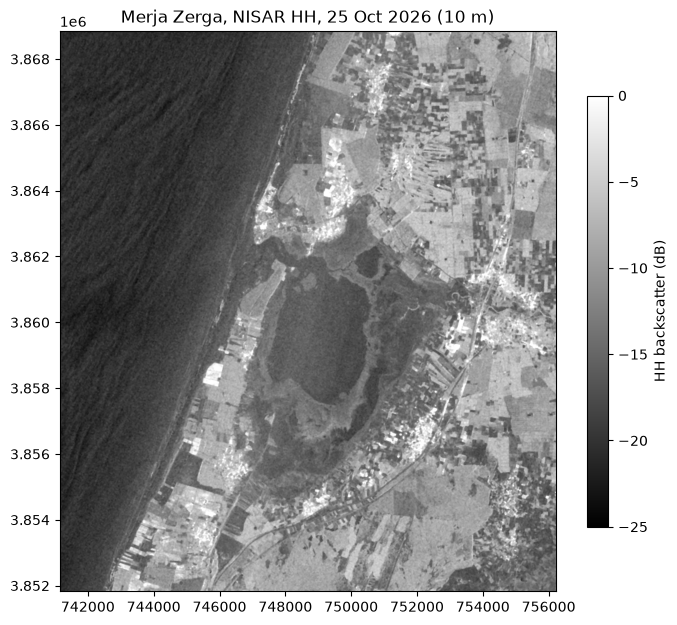

In [1]:
import glob, json, os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pyproj import Transformer
from scipy.ndimage import median_filter

# Merja Zerga lagoon (lon_min, lat_min, lon_max, lat_max)
BBOX = (-6.36, 34.78, -6.20, 34.93)
files = sorted(glob.glob("../data/raw/merja_zerga/*.h5"))   # 25 Oct first, 6 Nov second (when downloaded)
print("Files found:", [p.split("/")[-1][:60] for p in files])

def read_crop(path, bbox, pol="HHHH"):
    """Read only the bbox area from a NISAR GCOV file (frequency A). Returns dB image + coordinates."""
    with h5py.File(path, "r") as nisar:
        grid = nisar["science/LSAR/GCOV/grids/frequencyA"]
        x = grid["xCoordinates"][:]
        y = grid["yCoordinates"][:]
        epsg = int(grid["projection"].attrs["epsg_code"])
        to_map = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
        lon_min, lat_min, lon_max, lat_max = bbox
        xs, ys = to_map.transform([lon_min, lon_max, lon_min, lon_max], [lat_min, lat_min, lat_max, lat_max])
        cols = np.where((x >= min(xs)) & (x <= max(xs)))[0]
        rows = np.where((y >= min(ys)) & (y <= max(ys)))[0]
        power = grid[pol][rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
    db = 10 * np.log10(np.where(power > 0, power, np.nan))
    return db, x[cols[0]:cols[-1] + 1], y[rows[0]:rows[-1] + 1], epsg

def despeckle(img_db, size=5):
    """Reduce radar speckle with a median filter. Empty pixels (NaN) stay empty."""
    empty = np.isnan(img_db)
    filled = np.where(empty, np.nanmedian(img_db), img_db)
    smooth = median_filter(filled, size=size)
    smooth[empty] = np.nan
    return smooth

# BEFORE = 25 Oct 2026 (end of the dry season)
before_db, crop_x, crop_y, epsg = read_crop(files[0], BBOX)
before_smooth = despeckle(before_db)
extent = [crop_x[0], crop_x[-1], crop_y[-1], crop_y[0]]
print("Crop size:", before_smooth.shape, "| pixel: 10 m | EPSG:", epsg)

plt.figure(figsize=(8, 8))
plt.imshow(before_smooth, cmap="gray", vmin=-25, vmax=0, extent=extent)
plt.colorbar(label="HH backscatter (dB)", shrink=0.7)
plt.title("Merja Zerga, NISAR HH, 25 Oct 2026 (10 m)")
plt.show()

Otsu: -13.29 dB | final threshold: -15.0 dB
Water/wet area on 25 Oct: 44.5 %


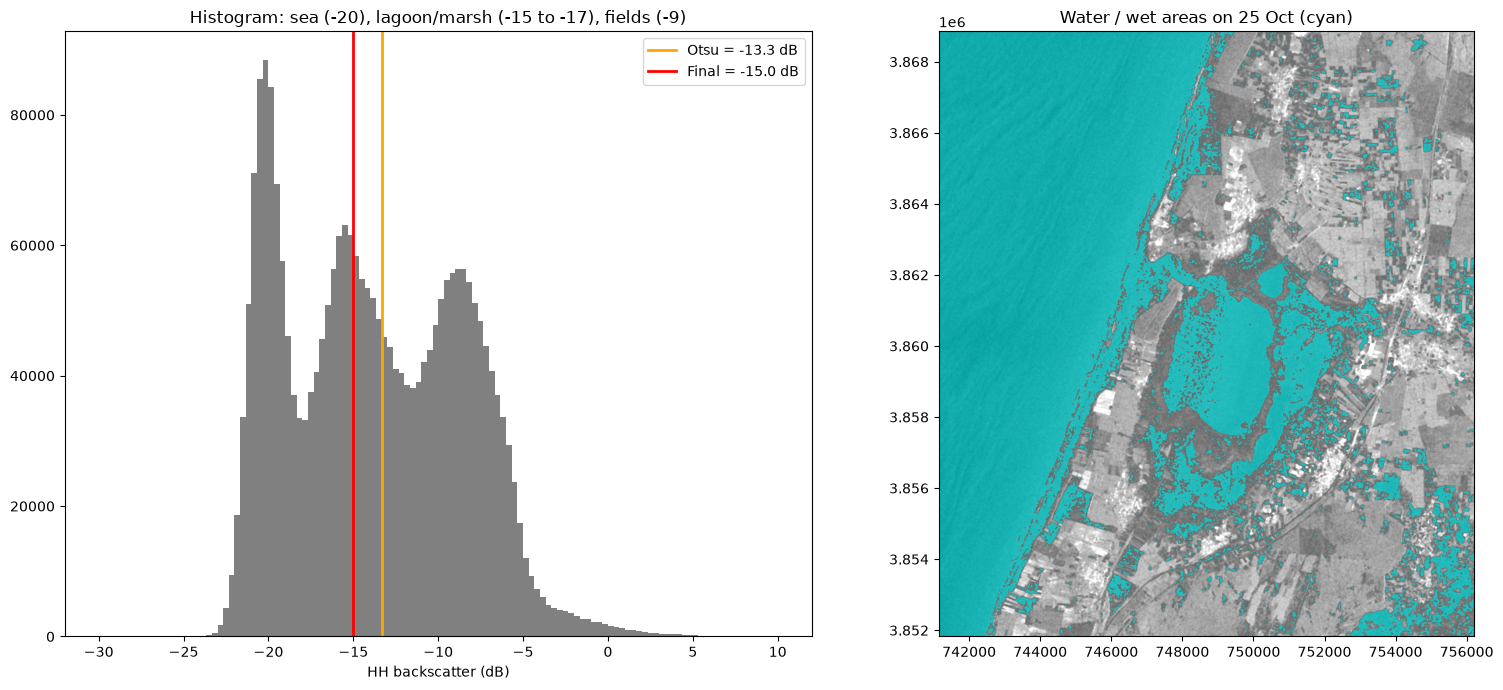

In [2]:
from skimage.filters import threshold_otsu

WATER_MAX_DB = -15.0   # physics guardrail: calm/shallow water in L-band HH is below about -15 dB

valid_pixels = before_smooth[np.isfinite(before_smooth)]
otsu = threshold_otsu(valid_pixels)
water_threshold = min(otsu, WATER_MAX_DB)
water_before = before_smooth < water_threshold

print("Otsu:", round(float(otsu), 2), "dB | final threshold:", water_threshold, "dB")
print("Water/wet area on 25 Oct:", round(float(np.nanmean(water_before) * 100), 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].hist(valid_pixels, bins=120, range=(-30, 10), color="gray")
axes[0].axvline(otsu, color="orange", linewidth=2, label=f"Otsu = {otsu:.1f} dB")
axes[0].axvline(water_threshold, color="red", linewidth=2, label=f"Final = {water_threshold:.1f} dB")
axes[0].set_xlabel("HH backscatter (dB)")
axes[0].set_title("Histogram: sea (-20), lagoon/marsh (-15 to -17), fields (-9)")
axes[0].legend()

axes[1].imshow(before_smooth, cmap="gray", vmin=-25, vmax=0, extent=extent)
axes[1].imshow(np.where(water_before, 1, np.nan), cmap="cool", alpha=0.6, extent=extent)
axes[1].set_title("Water / wet areas on 25 Oct (cyan)")
plt.tight_layout()
plt.show()

Multi-Otsu thresholds: [-17. -11.] dB
open water                  : 31.3 %
wet / low (lagoon, marsh)   : 34.8 %
land                        : 33.9 %


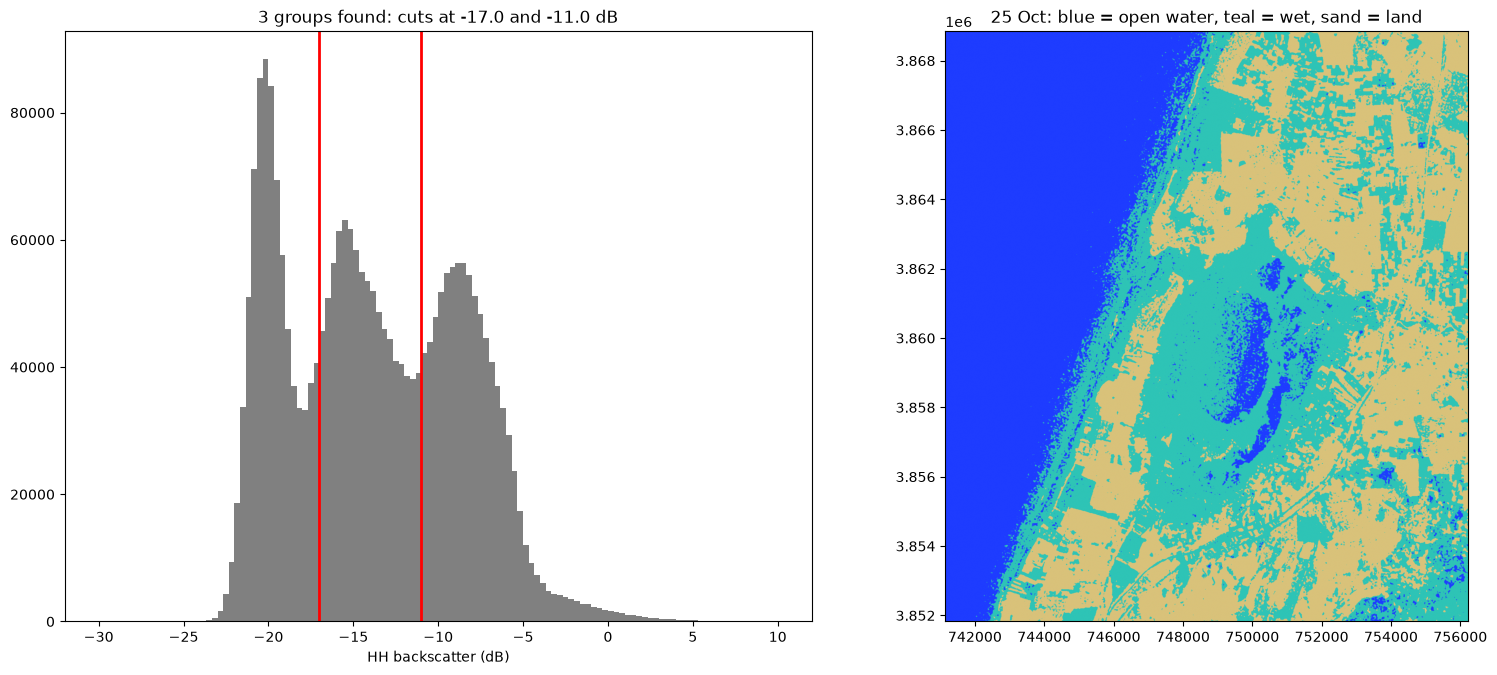

In [3]:
from skimage.filters import threshold_multiotsu
from matplotlib.colors import ListedColormap

# Multi-Otsu: find 2 thresholds -> 3 classes (open water / wet / land)
thresholds = threshold_multiotsu(before_smooth[np.isfinite(before_smooth)], classes=3)
print("Multi-Otsu thresholds:", np.round(thresholds, 1), "dB")

def classify(img_db, thresholds):
    """0 = open water, 1 = wet / low backscatter (lagoon, marsh), 2 = land. NaN stays NaN."""
    classes = np.digitize(img_db, thresholds).astype("float32")
    classes[np.isnan(img_db)] = np.nan
    return classes

classes_before = classify(before_smooth, thresholds)
names = ["open water", "wet / low (lagoon, marsh)", "land"]
for k, name in enumerate(names):
    print(f"{name:28s}: {np.nanmean(classes_before == k) * 100:.1f} %")

class_colors = ListedColormap(["#1e3cff", "#2ec4b6", "#d9c27a"])   # blue, teal, sand

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].hist(before_smooth[np.isfinite(before_smooth)], bins=120, range=(-30, 10), color="gray")
for t in thresholds:
    axes[0].axvline(t, color="red", linewidth=2)
axes[0].set_title(f"3 groups found: cuts at {thresholds[0]:.1f} and {thresholds[1]:.1f} dB")
axes[0].set_xlabel("HH backscatter (dB)")

axes[1].imshow(classes_before, cmap=class_colors, vmin=0, vmax=2, extent=extent)
axes[1].set_title("25 Oct: blue = open water, teal = wet, sand = land")
plt.tight_layout()
plt.show()

In [4]:
from PIL import Image
from rasterio.transform import from_origin
from rasterio.warp import calculate_default_transform, reproject, Resampling

OUT_DIR = "../public/data/merja_zerga"
os.makedirs(OUT_DIR, exist_ok=True)

def reproject_to_latlon(img, x, y, epsg, resampling=Resampling.bilinear):
    """Reproject a UTM image (pixel centers x, y) to lat/lon. Returns image + (south, west, north, east)."""
    pixel = abs(x[1] - x[0])
    height, width = img.shape
    left, top = x[0] - pixel / 2, y[0] + pixel / 2
    right, bottom = left + width * pixel, top - height * pixel
    src_transform = from_origin(left, top, pixel, pixel)
    dst_transform, dst_width, dst_height = calculate_default_transform(
        f"EPSG:{epsg}", "EPSG:4326", width, height, left, bottom, right, top)
    out = np.full((dst_height, dst_width), np.nan, dtype="float32")
    reproject(source=img.astype("float32"), destination=out,
              src_transform=src_transform, src_crs=f"EPSG:{epsg}",
              dst_transform=dst_transform, dst_crs="EPSG:4326",
              src_nodata=np.nan, dst_nodata=np.nan, resampling=resampling)
    west, north = dst_transform * (0, 0)
    east, south = dst_transform * (dst_width, dst_height)
    return out, (south, west, north, east)

def gray_rgba(img_db, vmin=-25, vmax=0):
    """Radar image -> grayscale RGBA, empty pixels transparent."""
    scaled = np.clip((img_db - vmin) / (vmax - vmin), 0, 1)
    gray = (np.nan_to_num(scaled) * 255).astype("uint8")
    alpha = np.where(np.isnan(img_db), 0, 255).astype("uint8")
    return np.dstack([gray, gray, gray, alpha])

CLASS_RGBA = {0: (30, 60, 255, 220), 1: (46, 196, 182, 200), 2: (0, 0, 0, 0)}   # land = transparent

def classes_rgba(classes):
    rgba = np.zeros(classes.shape + (4,), dtype="uint8")
    for value, color in CLASS_RGBA.items():
        rgba[classes == value] = color
    return rgba

# Export BEFORE now (AFTER comes when the 6 Nov file is downloaded)
before_ll, bounds = reproject_to_latlon(before_smooth, crop_x, crop_y, epsg)
classes_before_ll, _ = reproject_to_latlon(classes_before, crop_x, crop_y, epsg, resampling=Resampling.nearest)

Image.fromarray(gray_rgba(before_ll)).save(f"{OUT_DIR}/before.png")
Image.fromarray(classes_rgba(classes_before_ll)).save(f"{OUT_DIR}/classes_before.png")

print("Saved before.png and classes_before.png")
print("Bounds (south, west, north, east):", [round(v, 4) for v in bounds])

Saved before.png and classes_before.png
Bounds (south, west, north, east): [34.7764, -6.3648, 34.9336, -6.1949]
